In [23]:
from pathlib import Path
import numpy as np
import librosa
import matplotlib.pyplot as plt

SR = 16000
DATA = Path("data/kela")          # the notebook lives in scoring/
print("looking in:", DATA.resolve())

clips = {}
for p in sorted(DATA.glob("*.wav")):
    y, _ = librosa.load(p, sr=SR, mono=True)
    clips[p.stem] = y
    print(f"{p.stem:10} {len(y)/SR:4.2f}s   peak={np.abs(y).max():.2f}")

looking in: C:\Users\HP\Awaaz\backend\scoring\data\kela
correct_1  2.50s   peak=0.77
correct_2  2.50s   peak=0.64
correct_3  2.50s   peak=0.64
correct_4  2.50s   peak=0.66
correct_5  2.50s   peak=0.68
correct_6  2.50s   peak=0.74
other_1    2.50s   peak=0.61
other_2    2.50s   peak=0.94
other_3    2.50s   peak=0.77
other_4    2.50s   peak=0.58
wrong_1    2.50s   peak=0.57
wrong_2    2.50s   peak=0.57
wrong_3    2.50s   peak=0.63
wrong_4    2.50s   peak=0.57
wrong_5    2.50s   peak=0.78
wrong_6    2.50s   peak=0.98


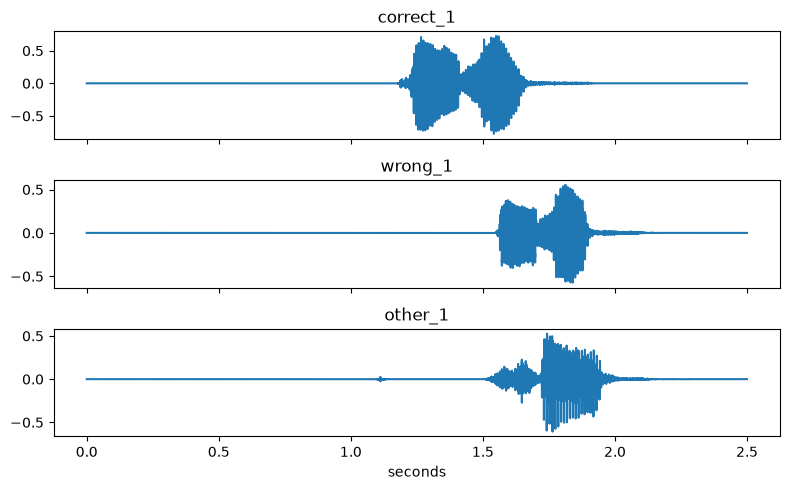

In [24]:
fig, axes = plt.subplots(3, 1, figsize=(8, 5), sharex=True)
for ax, name in zip(axes, ["correct_1", "wrong_1", "other_1"]):
    ax.plot(np.arange(len(clips[name])) / SR, clips[name])
    ax.set_title(name)
plt.xlabel("seconds")
plt.tight_layout()
plt.show()

In [25]:
def trim(y, top_db=30):
    trimmed, _ = librosa.effects.trim(y, top_db=top_db)
    return trimmed

for name, y in clips.items():
    t = trim(y)
    print(f"{name:10} {len(y)/SR:4.2f}s -> {len(t)/SR:4.2f}s")

correct_1  2.50s -> 0.61s
correct_2  2.50s -> 0.58s
correct_3  2.50s -> 0.58s
correct_4  2.50s -> 0.61s
correct_5  2.50s -> 0.64s
correct_6  2.50s -> 0.48s
other_1    2.50s -> 0.58s
other_2    2.50s -> 0.77s
other_3    2.50s -> 0.64s
other_4    2.50s -> 0.64s
wrong_1    2.50s -> 0.54s
wrong_2    2.50s -> 0.51s
wrong_3    2.50s -> 0.58s
wrong_4    2.50s -> 0.58s
wrong_5    2.50s -> 0.67s
wrong_6    2.50s -> 0.38s


In [26]:
from fastdtw import fastdtw
from scipy.spatial.distance import euclidean

def trim(y, top_db=30):
    return librosa.effects.trim(y, top_db=top_db)[0]

def features(y, n_mfcc=13):
    y = trim(y)                                   # remove silence
    y = y / (np.abs(y).max() + 1e-9)              # same loudness for every clip
    m = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=n_mfcc,
                             n_fft=400, hop_length=160, n_mels=40)
    m = m[1:]                                     # drop c0 (just loudness)
    m = (m - m.mean(axis=1, keepdims=True)) / (m.std(axis=1, keepdims=True) + 1e-9)  # CMVN
    return m.T                                    # rows = time frames

def dist(a, b):
    d, path = fastdtw(a, b, dist=euclidean)
    return d / len(path)                          # divide by path length

feats = {name: features(y) for name, y in clips.items()}

refs = [k for k in feats if k.startswith("correct")]
rows = []
for name, f in feats.items():
    ds = [dist(f, feats[r]) for r in refs if r != name]   # never compare a clip with itself
    rows.append((name.split("_")[0], name, float(np.mean(ds))))

for g in ["correct", "wrong", "other"]:
    vals = [d for grp, _, d in rows if grp == g]
    print(f"{g:8} {np.round(vals, 2)}   mean = {np.mean(vals):.2f}")

correct  [2.29 2.27 2.22 2.22 2.3  2.36]   mean = 2.28
wrong    [2.64 2.48 2.42 2.66 2.76 2.96]   mean = 2.65
other    [4.55 4.21 4.19 3.74]   mean = 4.18


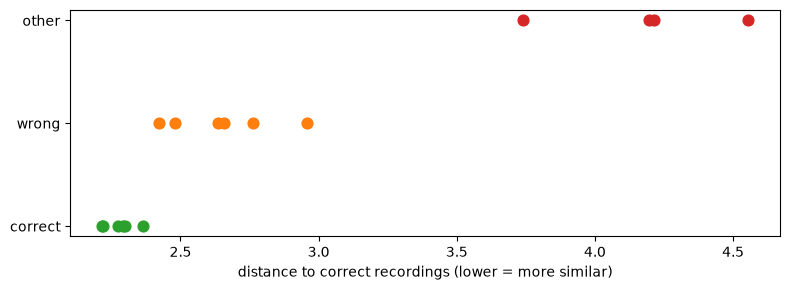

In [ ]:
colors = {"correct": "tab:green", "wrong": "tab:orange", "other": "tab:red"}
fig, ax = plt.subplots(figsize=(8, 3))
for i, g in enumerate(["correct", "wrong", "other"]):
    vals = [d for grp, _, d in rows if grp == g]
    ax.scatter(vals, [i] * len(vals), c=colors[g], s=60)
ax.set_yticks([0, 1, 2]); ax.set_yticklabels(["correct", "wrong", "other"])
ax.set_xlabel("distance to correct recordings (lower = more similar)")
plt.tight_layout(); plt.show()

In [28]:
def start_features(y, seconds=0.35):
    f = features(y)
    return f[: int(seconds * 100)]        # 10 ms per frame

sfeats = {name: start_features(y) for name, y in clips.items()}

rows2 = []
for name, f in sfeats.items():
    ds = [dist(f, sfeats[r]) for r in refs if r != name]
    rows2.append((name.split("_")[0], float(np.mean(ds))))

for g in ["correct", "wrong", "other"]:
    vals = [d for grp, d in rows2 if grp == g]
    print(f"{g:8} {np.round(vals, 2)}   mean = {np.mean(vals):.2f}")

correct  [2.73 2.47 2.42 2.57 2.49 3.03]   mean = 2.62
wrong    [2.82 2.72 2.55 2.86 2.91 4.32]   mean = 3.03
other    [4.94 5.08 5.01 4.73]   mean = 4.94
